# **Project Brazilian e-commerce by Olist**

# Data Cleaning

## Imports and Configs

In [2]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))
from src.eda_utils import *
from src.data_processing import *
from src.plots import *
import pandas as pd

In [3]:
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)

In [5]:
%run ../src/data_processing.py

2026-11-16 21:03:16,418 [INFO] Carregando customers de ..\data\raw\olist_customers_dataset.csv
2026-11-16 21:03:16,647 [INFO] Carregando orders de ..\data\raw\olist_orders_dataset.csv
2026-11-16 21:03:17,370 [INFO] Carregando order_items de ..\data\raw\olist_order_items_dataset.csv
2026-11-16 21:03:17,824 [INFO] Carregando payments de ..\data\raw\olist_order_payments_dataset.csv
2026-11-16 21:03:18,044 [INFO] Carregando reviews de ..\data\raw\olist_order_reviews_dataset.csv
2026-11-16 21:03:18,627 [INFO] Carregando products de ..\data\raw\olist_products_dataset.csv
2026-11-16 21:03:18,822 [INFO] Carregando sellers de ..\data\raw\olist_sellers_dataset.csv
2026-11-16 21:03:18,836 [INFO] Carregando geolocation de ..\data\raw\olist_geolocation_dataset.csv
2026-11-16 21:03:19,990 [INFO] Carregando category_translation de ..\data\raw\product_category_name_translation.csv
2026-11-16 21:03:20,371 [INFO] orders + customers -> (99441, 12)
2026-11-16 21:03:20,761 [INFO] + order_items -> (112650, 

In [ ]:
df_processed = pd.read_parquet("../data/int/olist_processed.parquet")
df_processed.head(3)

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,...,min_photos_qty,total_weight_g,max_weight_g,total_volume_cm3,max_item_volume_cm3,max_seller_distance_km,mean_seller_distance_km,n_sellers_missing_distance,min_seller_geo_n_points,max_seller_geo_n_points
0,00010242fe8c5a6d1ba2dd792cb16214,3ce436f183e68e07877b285a838db11a,delivered,2017-09-13 08:59:02,2017-09-13 09:45:35,2017-09-19 18:34:16,2017-09-20 23:43:48,2017-09-29,871766c5855e863f6eccc05f988b23cb,28013,...,4,650,650,3528,3528,301.229205,301.229205,0,59,59
1,00018f77f2f0320c557190d7a144bdd3,f6dd3ec061db4e3987629fe6b26e5cce,delivered,2017-04-26 10:53:06,2017-04-26 11:05:13,2017-05-04 14:35:00,2017-05-12 16:04:24,2017-05-15,eb28e67c4c0b83846050ddfb8a35d051,15775,...,2,30000,30000,60000,60000,588.404069,588.404069,0,39,39
2,000229ec398224ef6ca0657da4fc703e,6489ae5e4333f3693df5ad4372dab6d3,delivered,2018-01-14 14:33:31,2018-01-14 14:48:30,2018-01-16 12:36:48,2018-01-22 13:19:16,2018-02-05,3818d81c6709e39d06b2738a8d3a2474,35661,...,2,3050,3050,14157,14157,312.835023,312.835023,0,71,71


In [ ]:
df_processed = pd.read_parquet("../data/processed/olist_processed.parquet")
df_processed.head(3)

Quais colunas ainda têm nulos, e a origem é estrutural (ex.: pedido não entregue) ou erro de dado?

Sobraram valores impossíveis ou suspeitos, como total_price ≤ 0, peso ou volume extremos e n_items muito alto?

Qual a proporção de atrasados, e qual a magnitude do atraso (média, mediana, cauda)? Atrasos de 1 dia diferem de atrasos de 15 dias?

Qual a proporção de reviews ≤ 2 sobre os pedidos que têm review?

<Axes: title={'center': 'All categories — order_status'}, xlabel='order_status', ylabel='Count'>

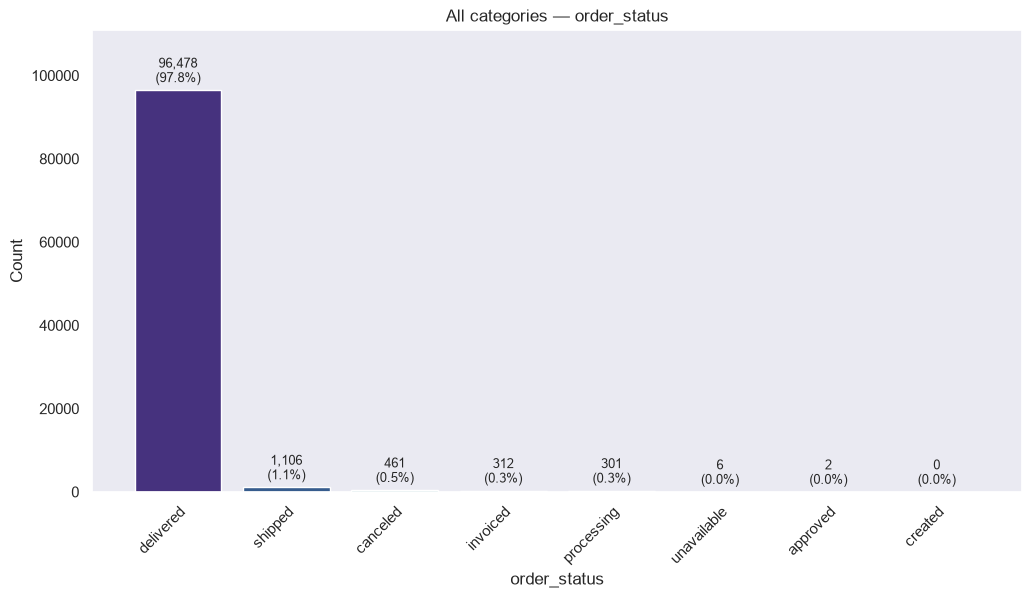

In [8]:
plot_categorical_counts(df_processed, "order_status", multicolor=True)

<Axes: title={'center': 'All categories — order_status'}, xlabel='order_status', ylabel='Count'>

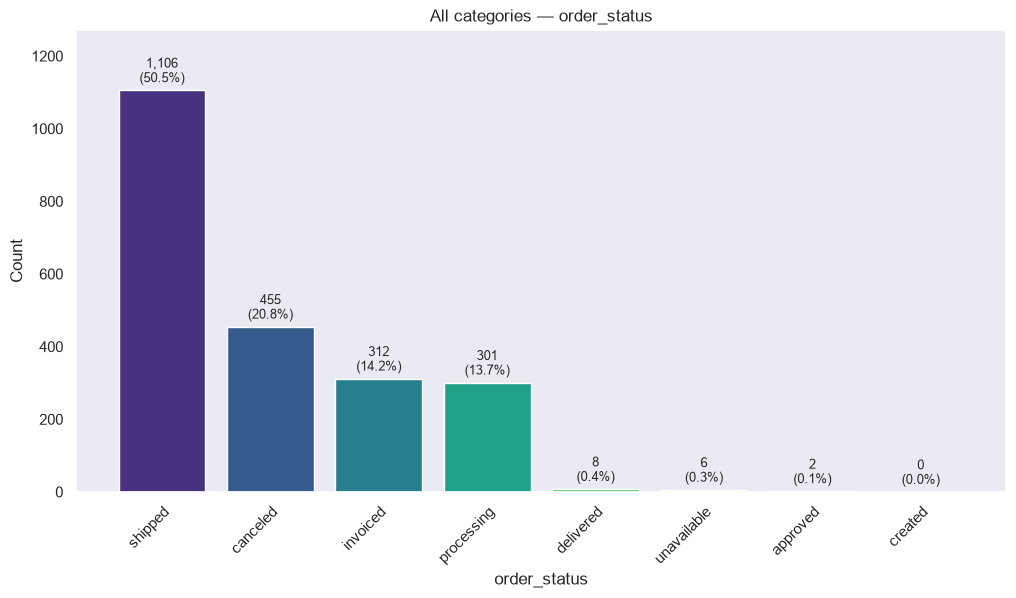

In [9]:
# Pedidos sem data de entrega
customer_date_null = df_processed["order_delivered_customer_date"].isna()
plot_categorical_counts(
    df_processed[customer_date_null], "order_status", multicolor=True
)

## Análise univariada
- Como se distribuem total_price, total_freight, total_weight_g, total_volume_cm3 e n_items? Há assimetria que pede transformação logarítmica?
- Quais variáveis têm outliers extremos, e eles são erro ou comportamento real (ex.: produtos caros ou pesados)?
- Qual a cardinalidade de main_category, estados e cidades? Quantas categorias são raras o bastante para agrupar em “outras”?
- Qual a distribuição de payment_types, payment_installments_max e n_payment_methods?
- Qual a proporção de pedidos multi-item, multi-vendedor e multi-categoria?
- Qual a distribuição de min_photos_qty, mean_name_length e mean_description_length? Há muitos zeros ou nulos?


## Análise temporal
- Como evolui o volume de pedidos por mês, e há sazonalidade (Black Friday, Natal)?
- A taxa de atraso e a de review ruim mudam ao longo do tempo (drift)? Isso afeta a estratégia de split temporal?
- Há períodos de dados incompletos nas pontas (2016 e fim de 2018) que devam ser excluídos?
- Há efeito de dia da semana ou hora da compra sobre atraso e review?
- Quanto tempo leva, em média, da compra à aprovação? Esse tempo varia com o meio de pagamento?
- O prazo estimado de entrega (estimated − purchase) é uma folga real ou um “colchão” inflado? 
- Quais regiões têm estimativas mais folgadas ou mais apertadas?

## Atraso (Modelo 1): bivariada
- A taxa de atraso varia por estado do cliente, estado do vendedor e rota (UF→UF)?
- A distância vendedor→cliente se relaciona com a taxa de atraso? A relação é monotônica ou tem limiar?
- Pedidos com vários vendedores ou vários estados de origem atrasam mais?
- Peso, volume e frete se relacionam com atraso? O freight_value é um bom proxy de logística?
- Certas categorias ou vendedores concentram o atraso? Há vendedores com muito volume e taxa alta (impacto operacional)?
- O prazo estimado ao cliente se relaciona com atraso, ou seja, o prazo longo realmente protege?
- O tempo até o vendedor postar (shipping_limit_date vs aprovação) tem relação com atraso, respeitando a regra de leakage?
- As 383 linhas de freight_value = 0 (já segmentadas por vendedor, categoria, preço e geografia) têm comportamento distinto de atraso?

## Review ruim (Modelo 2): bivariada
- A taxa de review ≤ 2 varia por categoria, estado, vendedor, faixa de preço e número de itens?
- Atributos do anúncio (fotos, tamanho de nome e descrição) se relacionam com review ruim?
- O meio de pagamento e o número de parcelas se relacionam com a nota?
- Pedidos multi-vendedor ou multi-item têm mais reviews ruins?
- Existem vendedores ou categorias com taxa persistentemente alta de review ruim, ou é só ruído de amostra pequena?
- Quão estável é a taxa por vendedor com poucos pedidos? Isso pede suavização ou um piso mínimo de volume?

## Hipótese atraso → review (validação observacional)
- Qual a taxa de review ≤ 2 entre pedidos atrasados versus no prazo?
- A relação é dose-resposta (mais dias de atraso, mais review ruim)? Há um ponto de inflexão?
- Parte dos reviews ruins ocorre sem atraso? Quais fatores explicam esse resíduo (categoria, preço, produto errado)?
- A relação se mantém dentro de categorias e estados (controle de confusores) ou desaparece?
- Pedidos não entregues ou cancelados concentram reviews ruins? Eles devem ficar de fora do Modelo 2?
- O texto de review_comment_message cita atraso, produto errado ou qualidade? Vale uma análise qualitativa de amostra para apoiar a narrativa de negócio?

## Relações entre variáveis
- Quais features numéricas são fortemente correlacionadas entre si (peso × volume × frete × preço)?
- Quais pares categóricos são redundantes (ex.: seller_states × n_seller_states)?
- Há variáveis quase constantes ou com variância desprezível?
- A associação entre features e alvo é linear ou pede modelos de árvore (XGBoost), como já esperado?

## Saídas para o notebook 2.0
- Quais correções determinísticas foram confirmadas e devem ir para src/data_processing.py?
- Quais transformações (log, agrupamento de categorias raras, flags de nulo) a EDA justificou?
- Quais features derivadas (distância, razão frete/preço, prazo estimado, flags de risco) a EDA sugeriu?
- Quais filtros de linha cada modelo exige, com o tamanho final de cada conjunto de treino?
- Qual estratégia de split (temporal ou aleatória estratificada) é adequada aos dados?